# Soal 2d · Lineage, Job–Stage–Task, dan pengaruh `cache()`
**Big Data** · **1 driver** di JupyterLab PC Master, **16 core** (4 Spark Worker). Pasangannya **Soal2_Master_Monitor.ipynb**
(`pantau()` dengan jeda 0 detik, sehingga waktu tidak terganggu).

| Bagian | Sel | Isi |
|---|---|---|
| Lineage | 3, 6 | `toDebugString()` sebelum dan sesudah `cache()` |
| Job–Stage–Task | 7 | tabel otomatis dari REST API Spark UI untuk setiap action |
| Pengaruh `cache()` | 4–6, 8 | 5 action yang sama dijalankan **tanpa** dan **dengan** cache; diukur waktu dan **jumlah baris yang di-parsing** (accumulator) |

Lima action per skenario:

| Kode | Action | Catatan |
|---|---|---|
| A1 | `parsed.count()` | pada skenario cache, action ini **mengisi** cache |
| A2 | (i) `takeOrdered(10)` wiki edit manusia | 2 stage (shuffle `reduceByKey`) |
| A3 | (ii) `takeOrdered(10)` halaman idwiki | 2 stage |
| A4 | (iii) `takeOrdered(15)` kata comment idwiki | 2 stage |
| A5 | `count()` pada RDD hasil A2 (objek yang **sama**) | stage sebelum shuffle **dilewati (skipped)**: Spark memakai ulang file shuffle A2, bahkan tanpa cache |

**Sebelum mulai:** halaman `http://192.168.1.15:8080` tanpa aplikasi aktif (driver 2c sudah `spark.stop()`);
di monitor jalankan Sel 1, Sel 4 (kosongkan), lalu Sel 3. Urutan notebook ini: **Sel 1 → 9**.

## Sel 1. SparkSession (16 core), REST API, `tandai()`, `report()`, `pantau()`

In [1]:
# ===== SEL 1: SparkSession dan fungsi bantu =====
import os, sys, socket, time, json, uuid, re, urllib.request
from datetime import datetime
from pathlib import Path
from operator import add
from pyspark import SparkContext
from pyspark.sql import SparkSession

MASTER_IP      = "192.168.1.15"
CORES_MAX      = 16
EXECUTOR_CORES = 4
EXECUTOR_MEM   = "2g"
MIN_PARTISI    = 2 * CORES_MAX          # 32 task di stage pertama
N_SHUFFLE      = CORES_MAX              # 16 task setelah reduceByKey
DATA_DIR       = "C:/BigData/data/snapshot_wiki"
PATH_ASLI      = f"file:///{DATA_DIR}/wiki_snapshot.jsonl"
PAKAI_MONITOR  = True
JEDA_PANTAU    = 0

s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.connect((MASTER_IP, 7077)); IP = s.getsockname()[0]; s.close()
EVENT_DIR = Path("spark-events").resolve(); EVENT_DIR.mkdir(exist_ok=True)

old = SparkContext._active_spark_context
if old is not None:
    try: old.stop()
    except Exception: pass
SparkSession._instantiatedSession = None
SparkSession._activeSession = None

spark = (SparkSession.builder
         .appName("Soal2d-lineage-cache")
         .master(f"spark://{MASTER_IP}:7077")
         .config("spark.driver.host", IP)
         .config("spark.driver.bindAddress", IP)
         .config("spark.cores.max", str(CORES_MAX))
         .config("spark.executor.cores", str(EXECUTOR_CORES))
         .config("spark.executor.memory", EXECUTOR_MEM)
         .config("spark.pyspark.python", sys.executable)
         .config("spark.pyspark.driver.python", sys.executable)
         .config("spark.ui.port", "4040")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", EVENT_DIR.as_uri())
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

def tandai(deskripsi):
    sc.setJobGroup(deskripsi.split()[0], deskripsi)

def api(path):
    url = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}"
    with urllib.request.urlopen(url, timeout=10) as r:
        return json.load(r)

REPORT_URL = f"http://{MASTER_IP}:8090"

def report(run, app, nomor, status):
    import json, os, socket, urllib.request
    data = {"run": run, "app": app, "task": nomor, "worker": socket.gethostname(),
            "pid": os.getpid(), "status": status}
    req = urllib.request.Request(REPORT_URL, data=json.dumps(data).encode("utf-8"),
                                 headers={"Content-Type": "application/json"}, method="POST")
    try:
        with urllib.request.urlopen(req, timeout=5) as r:
            return r.status == 200
    except Exception as e:
        print(f"Gagal melapor ke monitor: {e}")
        return False

def pantau(rdd, label, jeda=JEDA_PANTAU):
    if not PAKAI_MONITOR:
        return rdd
    run = str(uuid.uuid4())
    def proses_partition(idx, isi):
        import time
        report(run, label, idx, "RUNNING")
        data = list(isi)
        if jeda:
            time.sleep(jeda)
        report(run, label, idx, "DONE")
        return iter(data)
    return rdd.mapPartitionsWithIndex(proses_partition)

print("Spark   :", spark.version, "|", sc.master, "| driver", IP, "| core", CORES_MAX)
print("Spark UI:", sc.uiWebUrl, "| App ID:", sc.applicationId)
if PAKAI_MONITOR:
    try:
        with urllib.request.urlopen(REPORT_URL, timeout=3) as r:
            print("Monitor :", r.read().decode().strip())
    except Exception as e:
        print("PERINGATAN: monitor tidak terjangkau ->", e)

Spark   : 4.1.3 | spark://192.168.1.15:7077 | driver 192.168.1.15 | core 16
Spark UI: http://192.168.1.15:4040 | App ID: app-20261118211006-0040
Monitor : Monitor aktif. Jumlah laporan: 167


## Sel 2. Parsing dengan accumulator penghitung baris, stopword, dan pembangun RDD pertanyaan
`buat_parsed(acc)` membuat RDD hasil parsing yang setiap barisnya menambah `acc`. Karena accumulator diperbarui di transformation, nilainya bertambah **setiap kali parsing benar-benar dijalankan**: inilah alat ukur pengaruh cache yang tidak bergantung pada waktu.

In [2]:
# ===== SEL 2: Parser, stopword, dan pembangun RDD =====
WIKI, ID, TYPE, TITLE, USER, IS_ANON, BOT, MINOR, TS, LEN_OLD, LEN_NEW, COMMENT = range(12)

def _int(x):
    return isinstance(x, int) and not isinstance(x, bool)

def buat_parsed(acc, nama):
    def parse(baris):
        import json
        acc.add(1)                                   # satu baris benar-benar di-parsing
        try:
            e = json.loads(baris) if baris.strip() else None
        except ValueError:
            return []
        if not isinstance(e, dict) or not (
                _int(e.get("id")) and _int(e.get("timestamp"))
                and all(isinstance(e.get(k), str) and e.get(k) for k in ("wiki", "type", "title"))):
            return []
        return [(e["wiki"], e["id"], e["type"], e["title"], e.get("user"),
                 bool(e.get("is_anon", False)), bool(e.get("bot", False)), bool(e.get("minor", False)),
                 e["timestamp"], e.get("length_old"), e.get("length_new"), e.get("comment") or "")]
    return sc.textFile(PATH_ASLI, minPartitions=MIN_PARTISI).flatMap(parse).setName(nama)

STOPWORD = frozenset("""
ada adalah agar akan aku anda antara apa apakah atas atau bagi bahwa baik banyak baru bawah beberapa begitu belum
benar berapa bersama besar bila bisa boleh buat bukan dalam dan dapat dari dengan dia dulu hal hampir hanya harus
hingga ia ialah ini itu jadi jika juga justru kalau kami kamu karena kata ke kecil kembali kemudian kenapa kepada
ketika kita lagi lain lainnya lalu lama lebih maka masih masing melalui mana mau mereka merupakan meski mungkin
namun nanti nya oleh pada para paling per perlu pernah pula pun saat saja salah sama sambil sampai sangat saya
sebab sebagai sebagaimana sebelum sebuah secara sedang sehingga sejak sekali seluruh semua sendiri seorang seperti
sering serta sesuai setelah setiap siapa suatu sudah supaya tak tanpa tapi telah tentang tersebut tetap tetapi
tiap tidak untuk walau yaitu yakni yang dll dsb dst yg dgn utk tdk dr pd krn
the and of to in is for on with as by an be this that it from at or are was were has have had not but which also
its into than then there their they them these those been being will would can could should may might all any
some such only other more most very about after before over under between per via
""".split())
POLA_URL  = re.compile(r"https?://\S+|www\.\S+")
POLA_KATA = re.compile(r"[^\W\d_]+")

def tokenisasi(teks):
    teks = POLA_URL.sub(" ", teks.lower())
    return [k for k in POLA_KATA.findall(teks) if len(k) >= 3]

def bangun(src, kode, label=None):
    """RDD hasil reduceByKey untuk pertanyaan (i)/(ii)/(iii) dari RDD tuple `src`."""
    if kode == "i":
        pas = src.filter(lambda r: r[TYPE] == "edit" and not r[BOT]).map(lambda r: (r[WIKI], 1))
    elif kode == "ii":
        pas = src.filter(lambda r: r[WIKI] == "idwiki").map(lambda r: (r[TITLE], 1))
    else:
        pas = (src.filter(lambda r: r[WIKI] == "idwiki" and r[COMMENT])
                  .flatMap(lambda r: tokenisasi(r[COMMENT]))
                  .filter(lambda k: k not in STOPWORD)
                  .map(lambda k: (k, 1)))
    if label:
        pas = pantau(pas, f"{label} tahap 0 (narrow)")
    hasil = pas.reduceByKey(add, N_SHUFFLE).setName(f"hitung_{kode}")
    if label:
        hasil = pantau(hasil, f"{label} tahap 1 (wide)")
    return hasil

TOP_N = {"i": 10, "ii": 10, "iii": 15}
urut = lambda kv: (-kv[1], kv[0])
print("Siap. Stopword:", len(STOPWORD), "kata")

Siap. Stopword: 211 kata


## Sel 3. Lineage **sebelum** cache
Dibangun tanpa `pantau()` agar rantainya bersih. Lekukan baru yang diawali `+-` menandai **batas shuffle** = awal stage baru. Di PySpark, operasi narrow berurutan digabung menjadi satu `PythonRDD`.

In [3]:
# ===== SEL 3: Lineage sebelum cache =====
acc_lineage = sc.accumulator(0)
parsed_lin = buat_parsed(acc_lineage, "parsed")
for kode in ("i", "iii"):
    rdd = bangun(parsed_lin, kode)
    print(f"--- Lineage pertanyaan ({kode}) ---")
    print(rdd.toDebugString().decode())
    print()

--- Lineage pertanyaan (i) ---
(16) hitung_i PythonRDD[7] at RDD at PythonRDD.scala:59 []
 |   MapPartitionsRDD[6] at mapPartitions at PythonRDD.scala:171 []
 |   ShuffledRDD[5] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(32) PairwiseRDD[4] at reduceByKey at C:\Users\Administrator\AppData\Local\Temp\ipykernel_20656\4024365558.py:57 []
    |   PythonRDD[3] at reduceByKey at C:\Users\Administrator\AppData\Local\Temp\ipykernel_20656\4024365558.py:57 []
    |   file:///C:/BigData/data/snapshot_wiki/wiki_snapshot.jsonl MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |   file:///C:/BigData/data/snapshot_wiki/wiki_snapshot.jsonl HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []

--- Lineage pertanyaan (iii) ---
(16) hitung_iii PythonRDD[12] at RDD at PythonRDD.scala:59 []
 |   MapPartitionsRDD[11] at mapPartitions at PythonRDD.scala:171 []
 |   ShuffledRDD[10] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(32) PairwiseRDD[9] at red

## Sel 4. Pemanasan
Membaca file sekali (tanpa parsing) agar skenario pertama tidak dirugikan oleh disk yang masih "dingin".

In [4]:
# ===== SEL 4: Pemanasan =====
tandai("2d-pemanasan Baca file tanpa parsing")
t = time.time(); n = sc.textFile(PATH_ASLI, minPartitions=MIN_PARTISI).count()
print(f"Pemanasan: {n:,} baris dibaca dalam {time.time() - t:.2f} dtk")

Pemanasan: 222,241 baris dibaca dalam 15.44 dtk


## Sel 5. Skenario TANPA cache (5 action)

In [5]:
# ===== SEL 5: Skenario TANPA cache =====
def jalankan_skenario(sk, parsed, acc):
    hasil, catatan = {}, []
    def ukur(kode_aksi, deskripsi, fungsi):
        tandai(f"2d-{sk}-{kode_aksi} {deskripsi}")
        sebelum = acc.value
        t = time.time(); keluaran = fungsi(); d = time.time() - t
        catatan.append({"aksi": kode_aksi, "deskripsi": deskripsi, "detik": round(d, 2),
                        "baris_diparsing": acc.value - sebelum})
        print(f"{kode_aksi}  {deskripsi:<34}{d:>8.2f} dtk | baris di-parsing: {acc.value - sebelum:>9,}")
        return keluaran
    hasil["A1"] = ukur("A1", "count parsed", lambda: parsed.count())
    r_i = bangun(parsed, "i", f"2d-{sk}-A2 (i)")
    hasil["A2"] = ukur("A2", "(i) takeOrdered(10)", lambda: r_i.takeOrdered(10, key=urut))
    r_ii = bangun(parsed, "ii", f"2d-{sk}-A3 (ii)")
    hasil["A3"] = ukur("A3", "(ii) takeOrdered(10)", lambda: r_ii.takeOrdered(10, key=urut))
    r_iii = bangun(parsed, "iii", f"2d-{sk}-A4 (iii)")
    hasil["A4"] = ukur("A4", "(iii) takeOrdered(15)", lambda: r_iii.takeOrdered(15, key=urut))
    hasil["A5"] = ukur("A5", "count RDD (i) yang sama (A2)", lambda: r_i.count())
    total = sum(c["detik"] for c in catatan)
    print(f"{'':4}{'TOTAL':<34}{total:>8.2f} dtk | baris di-parsing: {acc.value:>9,}")
    return hasil, catatan, r_i

acc_nc = sc.accumulator(0)
parsed_nc = buat_parsed(acc_nc, "parsed_tanpa_cache")
print("=== TANPA cache ===")
hasil_nc, catat_nc, ri_nc = jalankan_skenario("nc", parsed_nc, acc_nc)

=== TANPA cache ===
A1  count parsed                         10.47 dtk | baris di-parsing:   222,241
A2  (i) takeOrdered(10)                 480.29 dtk | baris di-parsing:   315,843
A3  (ii) takeOrdered(10)                303.40 dtk | baris di-parsing:   321,939
A4  (iii) takeOrdered(15)               281.25 dtk | baris di-parsing:   295,666
A5  count RDD (i) yang sama (A2)         15.86 dtk | baris di-parsing:         0
    TOTAL                              1091.27 dtk | baris di-parsing: 1,155,689


## Sel 6. Skenario DENGAN cache (5 action yang sama) + lineage **sesudah** cache
A1 mengisi cache; A2–A4 membaca `parsed` dari memori executor.

In [6]:
# ===== SEL 6: Skenario DENGAN cache =====
acc_c = sc.accumulator(0)
parsed_c = buat_parsed(acc_c, "parsed_cache").cache()
print("=== DENGAN cache ===")
hasil_c, catat_c, ri_c = jalankan_skenario("c", parsed_c, acc_c)

print("\nHasil sama dengan skenario tanpa cache:",
      all([tuple(x) for x in hasil_nc[k]] == [tuple(x) for x in hasil_c[k]] if isinstance(hasil_nc[k], list)
          else hasil_nc[k] == hasil_c[k] for k in hasil_nc))

st = [r for r in api("storage/rdd") if r.get("name") == "parsed_cache"]
if st:
    r = st[0]
    print(f"Tab Storage: parsed_cache {r['numCachedPartitions']}/{r['numPartitions']} partisi di memori, "
          f"{r['memoryUsed'] / 1e6:.1f} MB, disk {r.get('diskUsed', 0) / 1e6:.1f} MB")

print("\n--- Lineage (i) SESUDAH cache (perhatikan CachedPartitions pada parsed_cache) ---")
print(bangun(parsed_c, "i").toDebugString().decode())

=== DENGAN cache ===
A1  count parsed                        208.79 dtk | baris di-parsing:   222,241
A2  (i) takeOrdered(10)                 433.79 dtk | baris di-parsing:   137,876
A3  (ii) takeOrdered(10)                144.77 dtk | baris di-parsing:         0
A4  (iii) takeOrdered(15)               138.63 dtk | baris di-parsing:         0
A5  count RDD (i) yang sama (A2)         16.18 dtk | baris di-parsing:         0
    TOTAL                               942.16 dtk | baris di-parsing:   360,117

Hasil sama dengan skenario tanpa cache: True
Tab Storage: parsed_cache 32/32 partisi di memori, 95.5 MB, disk 0.0 MB

--- Lineage (i) SESUDAH cache (perhatikan CachedPartitions pada parsed_cache) ---
(16) hitung_i PythonRDD[66] at RDD at PythonRDD.scala:59 []
 |   MapPartitionsRDD[65] at mapPartitions at PythonRDD.scala:171 []
 |   ShuffledRDD[64] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(32) PairwiseRDD[63] at reduceByKey at C:\Users\Administrator\AppData\Local\Temp\ipyke

## Sel 7. Tabel Job–Stage–Task untuk setiap action (dari REST API Spark UI)
Stage berstatus **SKIPPED** tidak dijalankan ulang karena hasil shuffle-nya sudah ada.

In [7]:
# ===== SEL 7: Tabel Job - Stage - Task =====
semua_job = api("jobs")
def baris_tabel(grup):
    jobs = sorted([j for j in semua_job if j.get("jobGroup") == grup], key=lambda j: j["jobId"])
    stage_teks, total_task, n_stage, n_skip = [], 0, 0, 0
    for j in jobs:
        for sid in sorted(j["stageIds"]):
            try:
                stg = api(f"stages/{sid}")[0]
                status, ntask = stg.get("status", "?"), stg.get("numTasks", 0)
            except Exception:
                status, ntask = "SKIPPED", 0
            n_stage += 1
            if status == "SKIPPED":
                n_skip += 1
                stage_teks.append(f"S{sid}:{ntask}t(skip)")
            else:
                total_task += ntask
                stage_teks.append(f"S{sid}:{ntask}t")
    return len(jobs), n_stage, n_skip, total_task, " ".join(stage_teks)

GRUP = [("2d-pemanasan", "pemanasan count textFile")]
for sk, nama in (("nc", "tanpa cache"), ("c", "dengan cache")):
    for c in (catat_nc if sk == "nc" else catat_c):
        GRUP.append((f"2d-{sk}-{c['aksi']}", f"{nama}: {c['aksi']} {c['deskripsi']}"))

print(f"{'Action':<48}{'Job':>4}{'Stage':>6}{'Skip':>5}{'Task':>6}  Rincian stage (task)")
TABEL_JST = []
for grup, nama in GRUP:
    nj, ns, nk, nt, rinci = baris_tabel(grup)
    TABEL_JST.append((nama, nj, ns, nk, nt, rinci))
    print(f"{nama:<48}{nj:>4}{ns:>6}{nk:>5}{nt:>6}  {rinci}")

Action                                           Job Stage Skip  Task  Rincian stage (task)
pemanasan count textFile                           1     1    0    32  S0:32t
tanpa cache: A1 count parsed                       1     1    0    32  S1:32t
tanpa cache: A2 (i) takeOrdered(10)                1     2    0    48  S2:32t S3:16t
tanpa cache: A3 (ii) takeOrdered(10)               1     2    0    48  S4:32t S5:16t
tanpa cache: A4 (iii) takeOrdered(15)              1     2    0    48  S6:32t S7:16t
tanpa cache: A5 count RDD (i) yang sama (A2)       1     2    1    16  S8:32t(skip) S9:16t
dengan cache: A1 count parsed                      1     1    0    32  S10:32t
dengan cache: A2 (i) takeOrdered(10)               1     2    0    48  S11:32t S12:16t
dengan cache: A3 (ii) takeOrdered(10)              1     2    0    48  S13:32t S14:16t
dengan cache: A4 (iii) takeOrdered(15)             1     2    0    48  S15:32t S16:16t
dengan cache: A5 count RDD (i) yang sama (A2)      1     2    1   

## Sel 8. Pengaruh `cache()`: waktu dan jumlah baris yang di-parsing

Aksi Deskripsi                        tanpa (dtk) dengan (dtk)  parse tanpa parse dengan
A1   count parsed                           10.47       208.79      222,241      222,241
A2   (i) takeOrdered(10)                   480.29       433.79      315,843      137,876
A3   (ii) takeOrdered(10)                  303.40       144.77      321,939            0
A4   (iii) takeOrdered(15)                 281.25       138.63      295,666            0
A5   count RDD (i) yang sama (A2)           15.86        16.18            0            0

Total 5 action      : tanpa 1091.27 dtk | dengan 942.16 dtk | 1.16x
A2-A4 (pakai ulang) : tanpa 1064.94 dtk | dengan 717.19 dtk | 1.48x
Baris di-parsing    : tanpa 1,155,689 | dengan 360,117


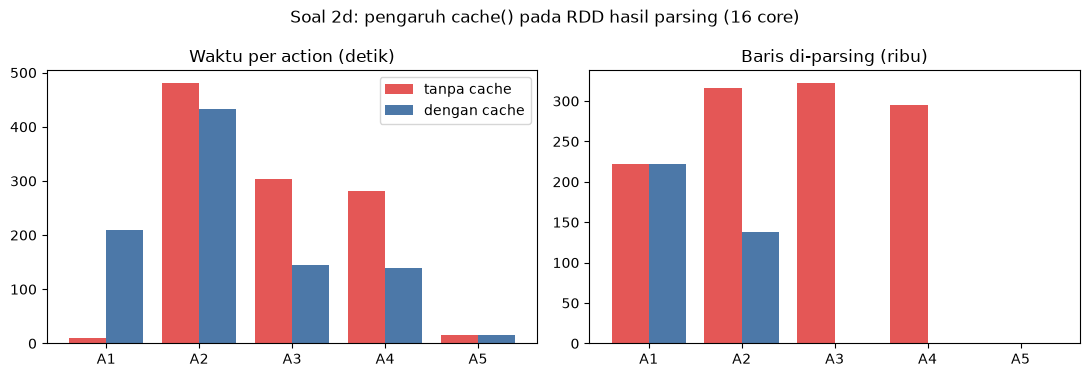

In [8]:
# ===== SEL 8: Perbandingan tanpa vs dengan cache =====
print(f"{'Aksi':<5}{'Deskripsi':<32}{'tanpa (dtk)':>12}{'dengan (dtk)':>13}{'parse tanpa':>13}{'parse dengan':>13}")
for a, b in zip(catat_nc, catat_c):
    print(f"{a['aksi']:<5}{a['deskripsi'][:31]:<32}{a['detik']:>12.2f}{b['detik']:>13.2f}"
          f"{a['baris_diparsing']:>13,}{b['baris_diparsing']:>13,}")
tn, tc = sum(c["detik"] for c in catat_nc), sum(c["detik"] for c in catat_c)
tn2, tc2 = sum(c["detik"] for c in catat_nc[1:4]), sum(c["detik"] for c in catat_c[1:4])
print(f"\nTotal 5 action      : tanpa {tn:.2f} dtk | dengan {tc:.2f} dtk | {tn / max(tc, 1e-9):.2f}x")
print(f"A2-A4 (pakai ulang) : tanpa {tn2:.2f} dtk | dengan {tc2:.2f} dtk | {tn2 / max(tc2, 1e-9):.2f}x")
print(f"Baris di-parsing    : tanpa {acc_nc.value:,} | dengan {acc_c.value:,}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = range(len(catat_nc)); w = 0.4
lab = [c["aksi"] for c in catat_nc]
ax[0].bar([i - w / 2 for i in x], [c["detik"] for c in catat_nc], w, label="tanpa cache", color="#E45756")
ax[0].bar([i + w / 2 for i in x], [c["detik"] for c in catat_c], w, label="dengan cache", color="#4C78A8")
ax[0].set(xticks=list(x), xticklabels=lab, title="Waktu per action (detik)"); ax[0].legend()
ax[1].bar([i - w / 2 for i in x], [c["baris_diparsing"] / 1000 for c in catat_nc], w, color="#E45756")
ax[1].bar([i + w / 2 for i in x], [c["baris_diparsing"] / 1000 for c in catat_c], w, color="#4C78A8")
ax[1].set(xticks=list(x), xticklabels=lab, title="Baris di-parsing (ribu)")
fig.suptitle("Soal 2d: pengaruh cache() pada RDD hasil parsing (16 core)")
fig.tight_layout()
Path("laporan").mkdir(exist_ok=True)
fig.savefig("laporan/2d_cache.png", dpi=120)
plt.show()

## Sel 9. Penutup

In [9]:
# ===== SEL 9: Penutup =====
print("Spark UI:", sc.uiWebUrl)
print("Screenshot: tab Jobs (label 2d-...), Stages, Storage (parsed_cache), DAG job 2d-c-A2 dan 2d-c-A5")
# parsed_c.unpersist(); spark.stop()   # buka komentar setelah screenshot selesai

Spark UI: http://192.168.1.15:4040
Screenshot: tab Jobs (label 2d-...), Stages, Storage (parsed_cache), DAG job 2d-c-A2 dan 2d-c-A5
